# Lab, Local Notebook: Visualize and Interpret

**GSB 5544 · Computing and Machine Learning for Business Analytics**

Open this notebook in **Positron, on your laptop**. It needs the three files you downloaded from your SageMaker space, in the same folder as this notebook:

- `lab_hot_days.csv`
- `lab_monthly_rain.csv`
- `lab_remote_measurements.json`

Everything here runs on your laptop. No cell in this notebook reads from S3.

In [10]:
# RUNS ON: laptop (Positron)
%pip install -q pandas pyarrow s3fs psutil matplotlib      # harmless if already present

import os
import json
import time
import socket
import psutil
import pandas as pd
import matplotlib.pyplot as plt

BUCKET = "noaa-ghcn-pds"


def human(n, base=1000):
    """Turn a byte count into a readable string. base=1000 gives KB/MB/GB; base=1024 gives KiB/MiB/GiB."""
    units = ["B", "KB", "MB", "GB", "TB", "PB"] if base == 1000 else ["B", "KiB", "MiB", "GiB", "TiB", "PiB"]
    for unit in units:
        if n < base:
            return f"{n:,.1f} {unit}"
        n /= base
    return f"{n:,.1f} (huge)"


def where_am_i():
    """Report which computer this kernel is really on. A RUNS ON comment cannot do that."""
    on_sagemaker = (os.path.exists("/opt/ml/metadata/resource-metadata.json")
                    or os.path.expanduser("~") == "/home/sagemaker-user")
    place = "SageMaker (remote)" if on_sagemaker else "not SageMaker (probably your laptop)"
    print("Computer name   :", socket.gethostname())
    print("This looks like :", place)
    return place


def machine_report(work_dir="."):
    """Measure the computer running this cell. Disk numbers are for the filesystem that holds work_dir."""
    vm = psutil.virtual_memory()
    du = psutil.disk_usage(work_dir)
    return {
        "computer name":                    socket.gethostname(),
        "physical CPU cores":               psutil.cpu_count(logical=False),   # may be None on some virtual machines
        "logical CPUs (vCPUs in the cloud)": psutil.cpu_count(logical=True),
        "total RAM (GB)":                   round(vm.total / 1e9, 1),
        "available RAM right now (GB)":     round(vm.available / 1e9, 1),
        "work disk, total (GB)":            round(du.total / 1e9, 1),
        "work disk, free (GB)":             round(du.free / 1e9, 1),
    }


if where_am_i() == "SageMaker (remote)":
    print()
    print("NOTE: this notebook is written to run on your laptop, in Positron, and this kernel is on SageMaker.")
    print("      Download this file and open it in Positron instead.")

Note: you may need to restart the kernel to use updated packages.
Computer name   : Lexis-MBP-3.lan
This looks like : not SageMaker (probably your laptop)


In [11]:
# RUNS ON: laptop (Positron)
NEEDED = ["lab_hot_days.csv", "lab_monthly_rain.csv", "lab_remote_measurements.json"]
missing = [name for name in NEEDED if not os.path.exists(name)]
print("This notebook is running in:", os.getcwd())
print("MISSING: " + ", ".join(missing) if missing else "All three downloaded files are here.")

This notebook is running in: /Users/lexihegarty/Documents/GSB-5544-Fall-2026-AGH/Labs
All three downloaded files are here.


## L8. Read what you downloaded

Read the two CSV files into `hot_days` and `monthly_rain`, and the JSON file into `REMOTE`. Print each table's shape and the size on disk of each downloaded file.

In [12]:
# RUNS ON: laptop (Positron)
# your code here
from pathlib import Path
hot_days = pd.read_csv("lab_hot_days.csv")
monthly_rain = pd.read_csv("lab_monthly_rain.csv")

with open("lab_remote_measurements.json", "r", encoding="utf-8") as f:
    REMOTE = json.load(f)

print("hot_days shape:", hot_days.shape)
print("monthly_rain shape:", monthly_rain.shape)

for filename in [
    "lab_hot_days.csv",
    "lab_monthly_rain.csv",
    "lab_remote_measurements.json",
]:
    size = Path(filename).stat().st_size
    print(f"{filename}: {size:,} bytes")


hot_days shape: (20, 4)
monthly_rain shape: (24, 4)
lab_hot_days.csv: 517 bytes
lab_monthly_rain.csv: 572 bytes
lab_remote_measurements.json: 178 bytes


## L9. Chart 1: hot days per year

One line per market: year on the x-axis, number of days at or above 35 °C on the y-axis. Label both axes with units, give the chart a title that says what it shows, and save it as `lab_hot_days.png`.

Before you plot, look at `days_reported`. If any market-year has far fewer than 365 reported days, say so in your interpretation in L11.

All market-years have at least 350 reported days.


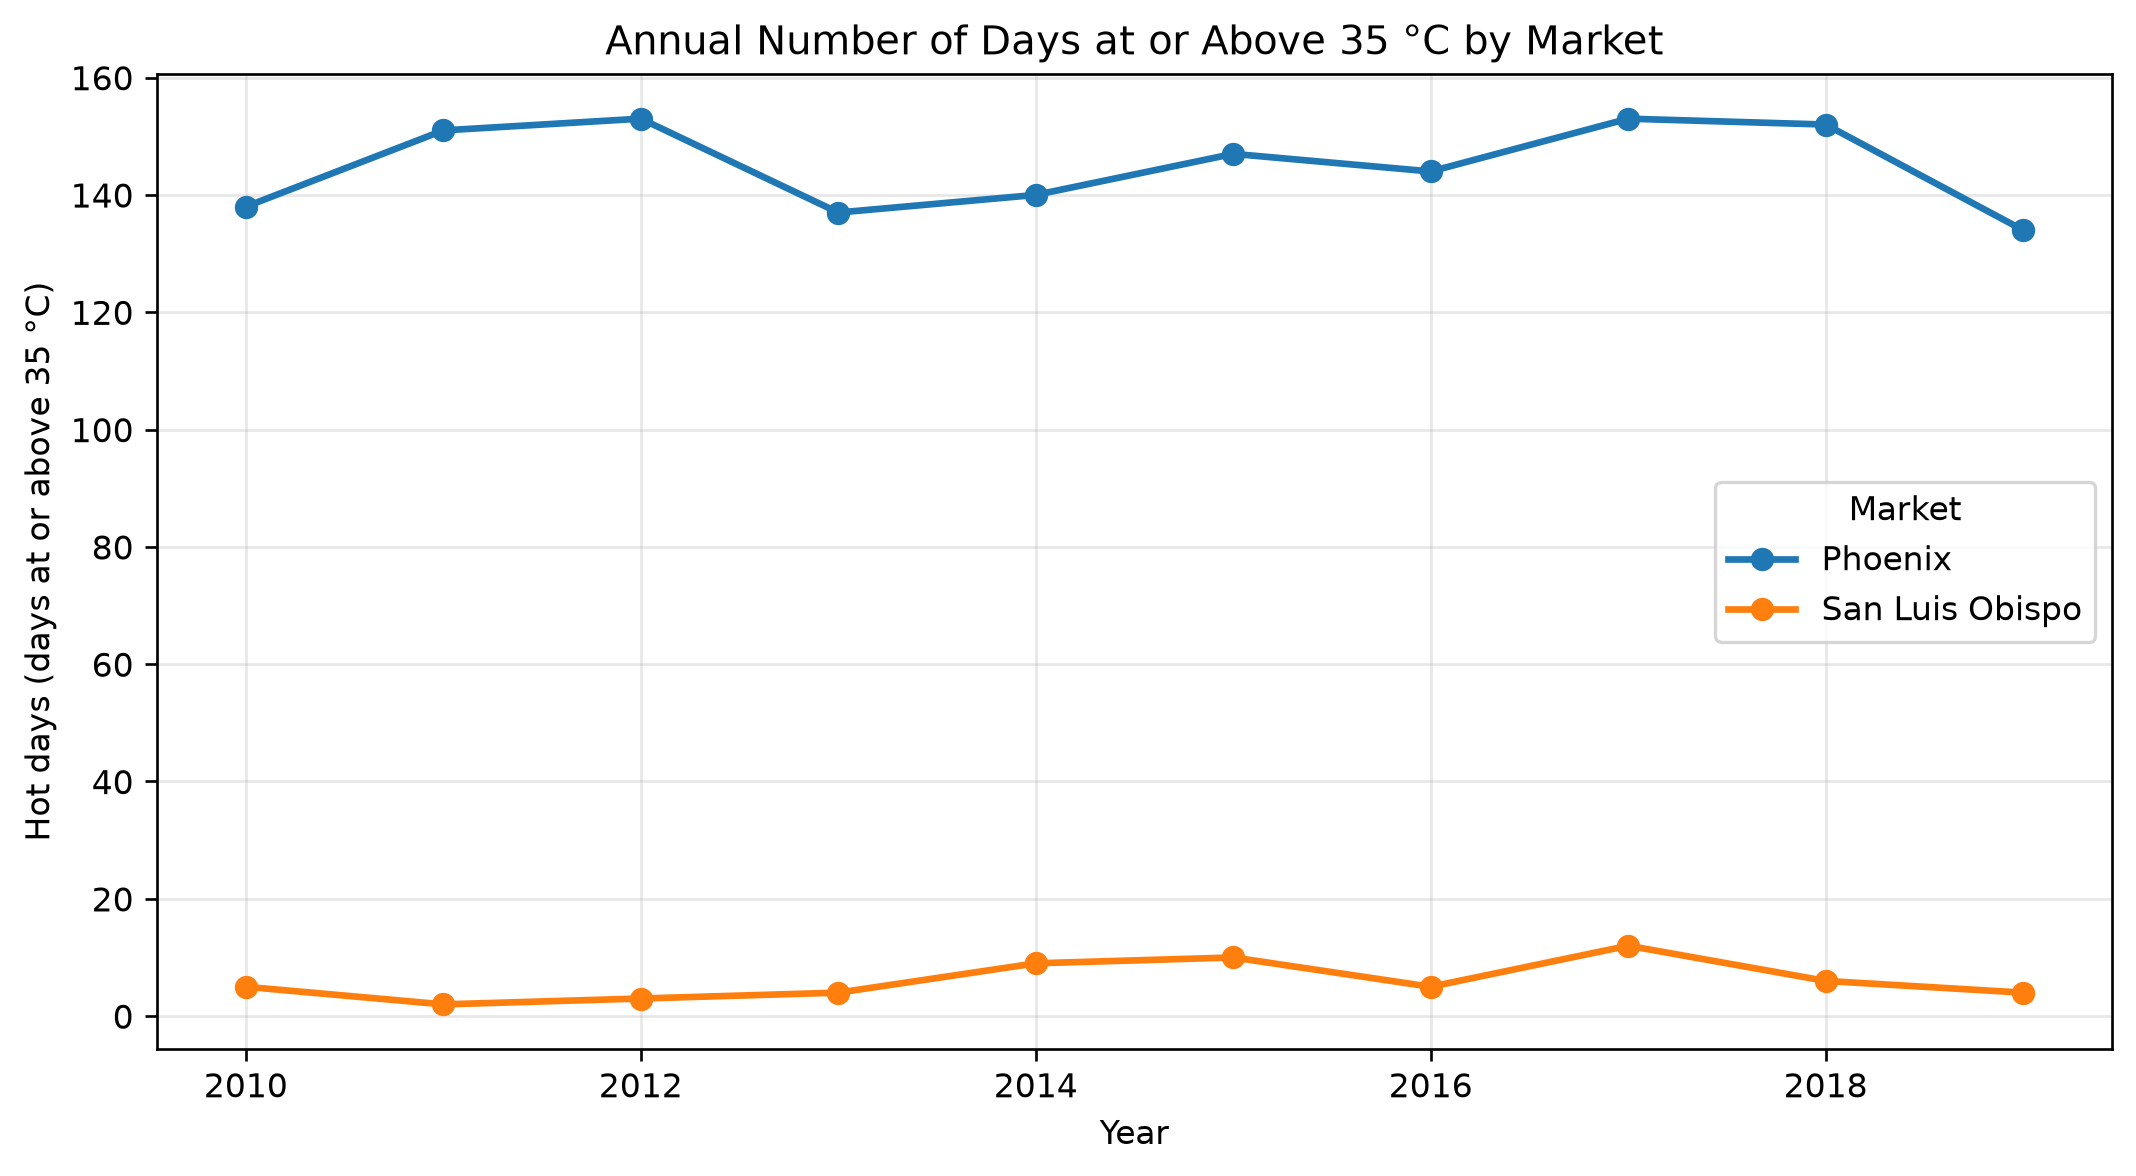

In [13]:
# RUNS ON: laptop (Positron)
# your code here
# Inspect reporting completeness first.
incomplete = hot_days.loc[
    hot_days["days_reported"] < 350,
    ["market", "year", "days_reported"],
]

if incomplete.empty:
    print("All market-years have at least 350 reported days.")
else:
    print("Market-years with substantially fewer than 365 reported days:")
    print(incomplete.to_string(index=False))

# Plot hot days by market and year.
fig, ax = plt.subplots(figsize=(9, 5))

for market, group in hot_days.groupby("market"):
    group = group.sort_values("year")
    ax.plot(
        group["year"],
        group["hot_days"],
        marker="o",
        linewidth=2,
        label=market,
    )

ax.set_xlabel("Year")
ax.set_ylabel("Hot days (days at or above 35 °C)")
ax.set_title("Annual Number of Days at or Above 35 °C by Market")
ax.legend(title="Market")
ax.grid(True, alpha=0.3)
fig.tight_layout()

fig.savefig("lab_hot_days.png", dpi=150)
plt.show()

## L10. Chart 2: typical rainfall by month

Show the average monthly precipitation for both markets across the twelve calendar months, in millimeters, in a form that makes the two markets easy to compare. Save it as `lab_monthly_rain.png`. Then print the wettest month of each market.

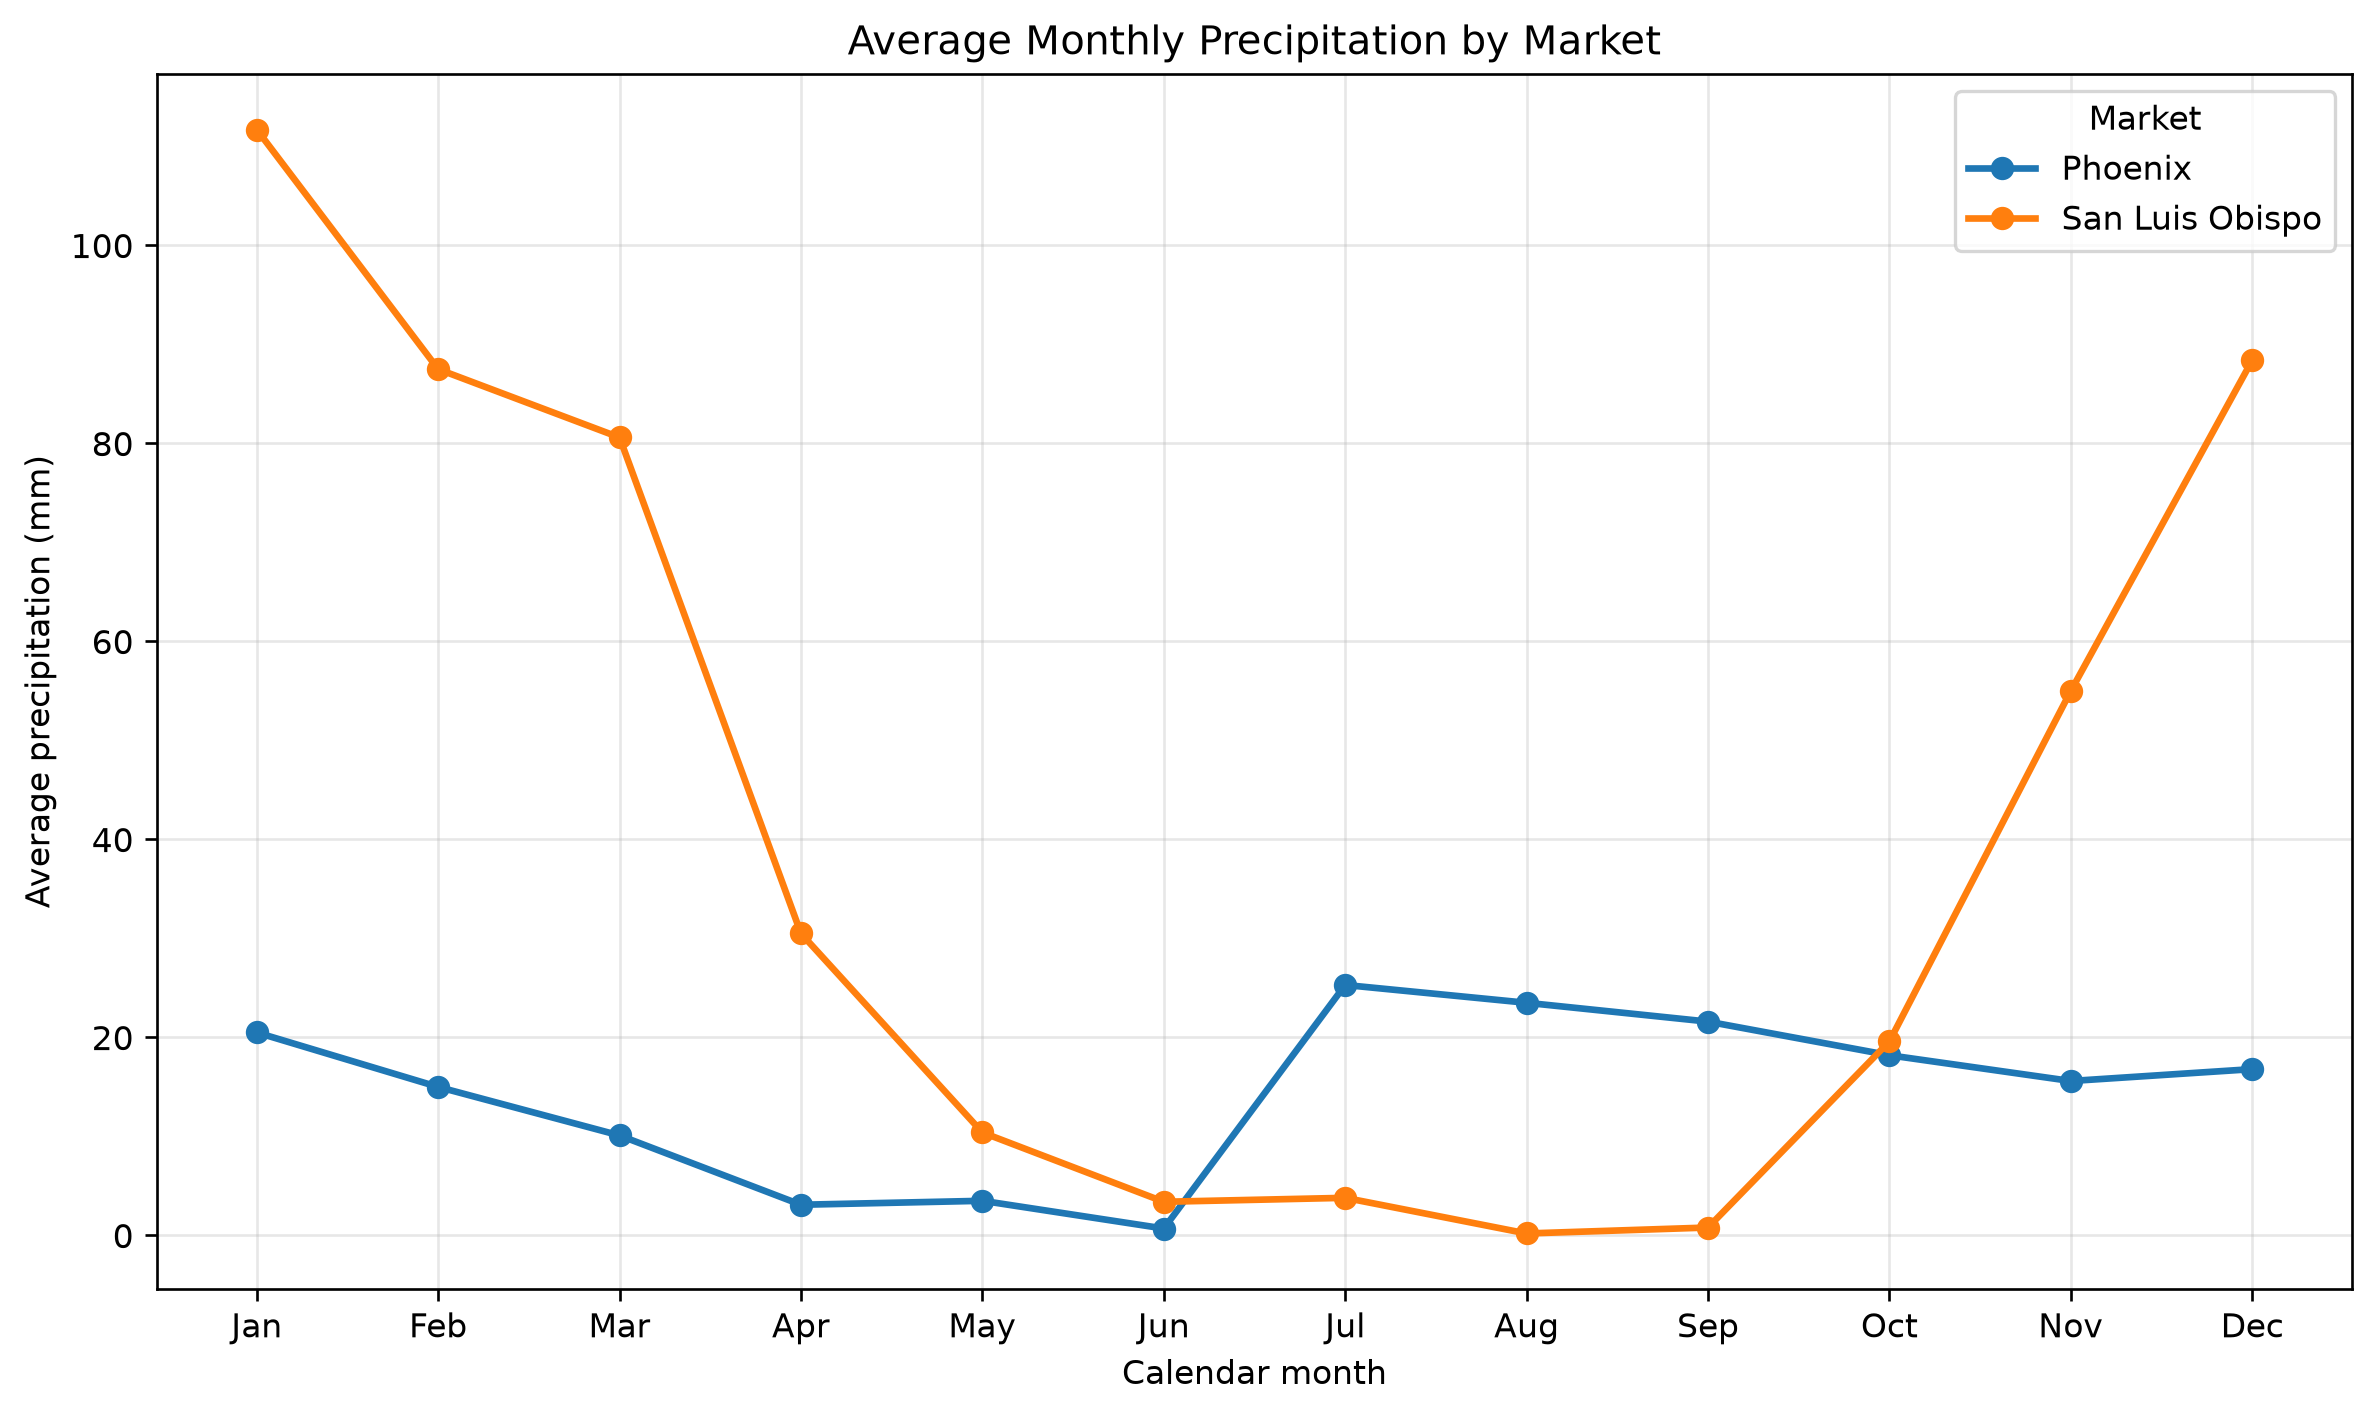

Wettest month of each market:
Phoenix: July (25.3 mm)
San Luis Obispo: January (111.7 mm)


In [14]:
import calendar
import matplotlib.pyplot as plt

monthly_rain["month"] = monthly_rain["month"].astype(int)
monthly_rain["avg_monthly_prcp_mm"] = pd.to_numeric(
    monthly_rain["avg_monthly_prcp_mm"]
)

fig, ax = plt.subplots(figsize=(10, 6))

for market, group in monthly_rain.groupby("market"):
    group = group.sort_values("month")
    ax.plot(
        group["month"],
        group["avg_monthly_prcp_mm"],
        marker="o",
        linewidth=2,
        label=market,
    )

ax.set_xticks(range(1, 13))
ax.set_xticklabels(list(calendar.month_abbr)[1:])
ax.set_xlabel("Calendar month")
ax.set_ylabel("Average precipitation (mm)")
ax.set_title("Average Monthly Precipitation by Market")
ax.legend(title="Market")
ax.grid(True, alpha=0.3)
fig.tight_layout()

fig.savefig("lab_monthly_rain.png", dpi=150)
plt.show()

print("Wettest month of each market:")

for market, group in monthly_rain.groupby("market"):
    wettest = group.loc[group["avg_monthly_prcp_mm"].idxmax()]
    print(
        f"{market}: "
        f"{calendar.month_name[int(wettest['month'])]} "
        f"({wettest['avg_monthly_prcp_mm']:.1f} mm)"
    )

## L11. The business read

Answer as the inventory planner, in six to eight sentences, using numbers from your two charts.

- How differently should the two markets be stocked across the year? Refer to both heat and rain.
- Is there anything in `days_reported` or `years_used` that should make the team cautious about a particular year or month?
- Name **two** other datasets you would want to join to this weather history before trusting a demand model, and say where each one probably lives: on a laptop, in a company database, or in cloud storage.

*Your answer:*
Phoenix should be stocked differently from San Luis Obispo: Phoenix has roughly 137–153 days per year at or above 35 °C, while San Luis Obispo has only about 2–12. Phoenix has less rainfall. with monthly rainfall generally around 0–25 mm. San Luis Obispo ranges from about 0 mm in August to roughly 112 mm in January. I would emphasize heated inventory planning in Phoenix during the hottest period and weatherproof or rain-sensitive inventory in San Luis Obispo during its winter peak. Before trusting any particular year, I would check days_reported and be note years with substantially fewer than 365 observations. I would also check years_used, since a monthly average based on fewer complete years is less reliable.

## L12. Two machines and four sizes

Build one table that puts your laptop's `machine_report()` beside the remote machine's (from `REMOTE["machine"]`). Then print, in readable units: the source size in S3, the size of the remote DataFrame, the combined size of the exported CSVs, and the combined size of the files as downloaded on this laptop.

In [17]:
# RUNS ON: laptop (Positron)

from pathlib import Path
import pandas as pd

laptop_report = machine_report()

remote_report = {
    "computer name": "default",
    "physical CPU cores": 1,
    "logical CPUs (vCPUs in the cloud)": 2,
    "total RAM (GB)": 4.0,
    "available RAM right now (GB)": 1.4,
    "work disk, total (GB)": 5.3,
    "work disk, free (GB)": 5.2,
}

machine_table = pd.DataFrame({
    "laptop": pd.Series(laptop_report),
    "remote SageMaker": pd.Series(remote_report),
})

print(machine_table)

source_bytes = REMOTE["source bytes in S3"]
remote_dataframe_bytes = REMOTE["DataFrame bytes"]

exported_csv_bytes = (
    Path("lab_hot_days.csv").stat().st_size
    + Path("lab_monthly_rain.csv").stat().st_size
)

downloaded_file_bytes = sum(
    Path(filename).stat().st_size
    for filename in [
        "lab_hot_days.csv",
        "lab_monthly_rain.csv",
        "lab_remote_measurements.json",
    ]
)

print("\nFile sizes:")
print(f"Source size in S3:           {human(source_bytes)}")
print(f"Remote DataFrame:            {human(remote_dataframe_bytes)}")
print(f"Exported CSVs combined:      {human(exported_csv_bytes)}")
print(f"Downloaded files combined:   {human(downloaded_file_bytes)}")

                                            laptop remote SageMaker
computer name                      Lexis-MBP-3.lan          default
physical CPU cores                              11                1
logical CPUs (vCPUs in the cloud)               11                2
total RAM (GB)                                19.3              4.0
available RAM right now (GB)                   4.7              1.4
work disk, total (GB)                        494.4              5.3
work disk, free (GB)                         242.6              5.2

File sizes:
Source size in S3:           356.5 MB
Remote DataFrame:            2.8 MB
Exported CSVs combined:      1.1 KB
Downloaded files combined:   1.3 KB


## L13. Where the work happened

**(a)** Answer each of the five questions in one or two sentences, with specifics from this lab.

1. **Where is the original data stored?**
2. **Which computer performed the analysis?**
3. **What did I download?**
4. **Which computer created the visualization?**
5. **How did the two machines compare?**

*Your answers:*
(1) the oringal data is stored in s3 bucket accessed through sage maker
(2) my laptop performed the analysis
(3) I downloaded csvs that had just the data I wanted.
(4) my laptop did the visualozation
(5) My laptop had 11 CPU cores, 19.3 GB of total RAM, and 242.6 GB of free disk space. SageMaker had 1 physical core, 2 vCPUs, 4.0 GB of RAM, and 5.2 GB of free disk space. Therefore, SageMaker was the constrained machine used for remote extraction, while the more capable laptop handled the lightweight plotting and reporting.

**(b)** This weather summary will be refreshed **every week** once the demand model is live. Would you run the weekly refresh on your laptop or on a SageMaker space? Give two reasons that use what you measured: the source size, the size of what comes home, the resources of each machine, and the cost from L7.

*Your answer:*
I would run the weekly refresh on SageMaker. The source is 356.5 MB, but only about 1.3 KB of summaries and metadata need to come home, so processing remotely avoids repeatedly transferring the source data to my laptop. SageMaker is smaller than my laptop—4.0 GB RAM and 2 vCPUs versus 19.3 GB RAM and 11 cores—but it handled the extraction successfully. At approximately $0.05 per hour, a short weekly run would cost very little, especially if I stop the SageMaker space immediately afterward.
 

## L14. Save and stop

- [ ] **Remote notebook:** File → **Save Notebook**. Right-click it in the JupyterLab file browser and **Download** a copy.
- [ ] **Studio tab:** on the `gsb5544` space page click **Stop space**, confirm in the dialog, and wait until the status reads **Stopped**. Closing the browser tab does not stop it.
- [ ] **Console Home** (open [console.aws.amazon.com](https://console.aws.amazon.com) in a new tab): read **Credits remaining** and note it. The panel can lag by several hours.
- [ ] **Laptop:** save your local notebook in Positron (Cmd+S, or Ctrl+S on Windows).

Paste a screenshot of the `gsb5544` space page showing status **Stopped** into the cell below, or submit it as a separate image.

*Evidence:*

## What to submit

1. `04_lab_remote.ipynb`, run in SageMaker, with output showing.
2. `04_lab_local.ipynb` (this notebook), run in Positron, with output and written answers.
3. `lab_hot_days.csv` and `lab_monthly_rain.csv`.
4. `lab_hot_days.png` and `lab_monthly_rain.png`.
5. The screenshot showing the space **Stopped**.

A submission is graded on both halves. A lab whose charts were made on SageMaker, or whose summaries were computed on a laptop, has not done the workflow.